# Module 4 - Data Set Repair

**Name:** Clement Scaccia  
**Course:** Data Visualization  
**Tool:** Python (pandas, matplotlib) in Jupyter Lab

For this module I picked 2 of my 4 data sets from Module 3:

1. **Government:** US Consumer Price Index (CPI-U) from the Bureau of Labor Statistics, `data/government/us_cpi_monthly_bls.csv`
2. **Commercial:** Cboe VIX volatility index, `data/commercial/cboe_vix_daily.csv`

I picked these two because they're the ones I'd actually use for finance work, and when I checked them they both had real problems that would give wrong charts or wrong numbers if I didn't fix them. For each one I **find** the problem with code, **fix** it, and **check** that the fix worked. The raw files are never changed. The cleaned versions are saved in `Module4/cleaned_data/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW = "../data"
OUT = "cleaned_data"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

cpi_raw = pd.read_csv(f"{RAW}/government/us_cpi_monthly_bls.csv", parse_dates=["Date"])
vix_raw = pd.read_csv(f"{RAW}/commercial/cboe_vix_daily.csv", parse_dates=["DATE"])
print("CPI:", cpi_raw.shape, " VIX:", vix_raw.shape)

CPI: (1364, 3)  VIX: (9278, 5)


---
# Data Set 1: US CPI (Government)

## Failure 1: a month is missing (October 2025)

CPI is supposed to be one row per month with no gaps. I built the full list of months from the first date to the last one and compared it to the data.

In [2]:
full_months = pd.date_range(cpi_raw["Date"].min(), cpi_raw["Date"].max(), freq="MS")
missing = full_months.difference(cpi_raw["Date"])
print("Expected months:", len(full_months), "| Rows in file:", len(cpi_raw))
print("Missing months:", list(missing.strftime("%Y-%m")))
cpi_raw[(cpi_raw["Date"] >= "2025-08-01") & (cpi_raw["Date"] <= "2025-12-01")]

Expected months: 1365 | Rows in file: 1364
Missing months: ['2025-10']


,Date,Index,Inflation
1351,2025-08-01,323.976,0.29
1352,2025-09-01,324.800,0.25
1353,2025-11-01,324.122,-0.21
1354,2025-12-01,324.054,-0.02


**Why it happened:** this isn't a mistake in the file. Because of the federal government shutdown in fall 2025, BLS couldn't collect prices for October 2025 and never published an October CPI (BLS FAQ: https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm).

**Why it's a problem:** a line chart just connects September to November like nothing's missing, and anything that counts rows to measure time (like "12 rows back = 1 year ago") is now off by one month for every date after October 2025.

**Fix:** I put the missing month back in so the timeline is complete. I estimated its Index value with **linear interpolation** (halfway between September and November) and added an `Estimated` column so it's clear this value isn't official BLS data.

In [3]:
cpi = cpi_raw.set_index("Date").reindex(full_months)
cpi.index.name = "Date"
cpi["Estimated"] = cpi["Index"].isna()
cpi["Index"] = cpi["Index"].interpolate(method="linear").round(3)
cpi = cpi.reset_index()
cpi[(cpi["Date"] >= "2025-08-01") & (cpi["Date"] <= "2025-12-01")]

,Date,Index,Inflation,Estimated
1351,2025-08-01,323.976,0.29,False
1352,2025-09-01,324.800,0.25,False
1353,2025-10-01,324.461,NaN,True
1354,2025-11-01,324.122,-0.21,False
1355,2025-12-01,324.054,-0.02,False


## Failure 2: the `Inflation` column is misleading (and wrong for November 2025)

Two problems with this column:

1. **It isn't what most people mean by inflation.** The file's documentation says it's the **month over month** % change. When people say "inflation is 3%," they mean the change over **12 months**. Someone who just reads the column name would get it badly wrong (for example, 0.59 for Sep 2026 looks like inflation is under 1%, but the real yearly rate is about 4%).
2. **Because of Failure 1, the November 2025 value is wrong.** It was calculated against the previous row, which was September, so it's really a **2-month** change labeled as a 1-month change.

In [4]:
nov = cpi_raw[cpi_raw["Date"] == "2025-11-01"]
sep = cpi_raw[cpi_raw["Date"] == "2025-09-01"]
print("File says Nov 2025 'Inflation' =", nov["Inflation"].iloc[0])
print("Change from Sep -> Nov (2 months) =", round((nov["Index"].iloc[0] / sep["Index"].iloc[0] - 1) * 100, 2))

File says Nov 2025 'Inflation' = -0.21
Change from Sep -> Nov (2 months) = -0.21


**Fix:** I recalculated the monthly change from the repaired Index (so every row is truly a 1-month change), renamed it `MoM_Change_%` so the name says what it is, and added a `YoY_Inflation_%` column (12-month change), which is the number people actually use. The first rows stay empty on purpose, since there's no earlier data to compare with. Oct and Nov 2025 are flagged in a `MoM_Uses_Estimate` column because they depend on the estimated October value.

In [5]:
cpi = cpi.drop(columns="Inflation")
cpi["MoM_Change_%"] = (cpi["Index"].pct_change() * 100).round(2)
cpi["YoY_Inflation_%"] = (cpi["Index"].pct_change(12) * 100).round(2)
cpi["MoM_Uses_Estimate"] = cpi["Estimated"] | cpi["Estimated"].shift(1, fill_value=False)
cpi = cpi[["Date", "Index", "MoM_Change_%", "YoY_Inflation_%", "Estimated", "MoM_Uses_Estimate"]]
cpi.tail(12)

,Date,Index,MoM_Change_%,YoY_Inflation_%,Estimated,MoM_Uses_Estimate
1353,2025-10-01,324.461,-0.10,2.79,True,True
1354,2025-11-01,324.122,-0.10,2.74,False,True
1355,2025-12-01,324.054,-0.02,2.68,False,False
1356,2026-01-01,325.252,0.37,2.39,False,False
1357,2026-02-01,326.785,0.47,2.41,False,False
1358,2026-03-01,330.213,1.05,3.26,False,False
1359,2026-04-01,333.020,0.85,3.81,False,False
1360,2026-05-01,335.123,0.63,4.25,False,False
1361,2026-06-01,333.952,-0.35,3.53,False,False
1362,2026-07-01,333.918,-0.01,3.36,False,False


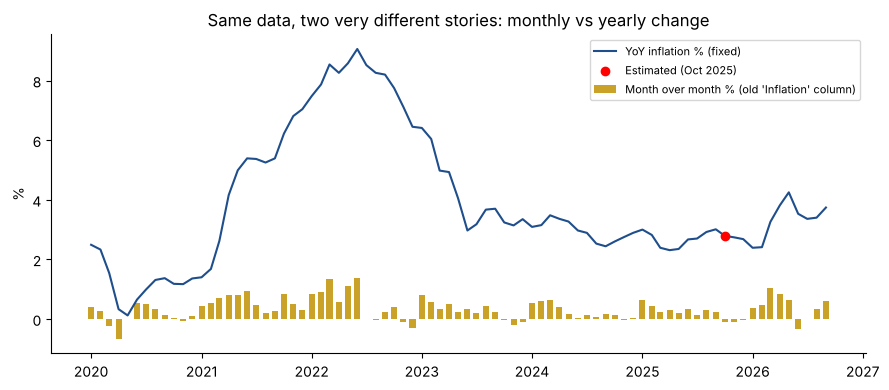

In [6]:
fig, ax = plt.subplots()
recent = cpi[cpi["Date"] >= "2020-01-01"]
ax.plot(recent["Date"], recent["YoY_Inflation_%"], label="YoY inflation % (fixed)", color="#1f4e8c")
ax.bar(recent["Date"], recent["MoM_Change_%"], width=20, label="Month over month % (old 'Inflation' column)", color="#c9a227")
est = recent[recent["Estimated"]]
ax.scatter(est["Date"], est["YoY_Inflation_%"], color="red", zorder=3, label="Estimated (Oct 2025)")
ax.set_title("Same data, two very different stories: monthly vs yearly change")
ax.set_ylabel("%")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Check CPI

In [7]:
assert cpi["Date"].diff().dropna().dt.days.between(28, 31).all(), "gap in months"
assert len(cpi) == len(full_months)
assert cpi["Index"].isna().sum() == 0
assert cpi["Estimated"].sum() == 1
print("CPI checks passed: every month present, 1 estimated value, no missing Index values")
cpi.to_csv(f"{OUT}/us_cpi_monthly_bls_cleaned.csv", index=False)

CPI checks passed: every month present, 1 estimated value, no missing Index values


---
# Data Set 2: Cboe VIX (Commercial)

Each row is supposed to be one trading day with the Open, High, Low and Close of the VIX. For real market data, two rules always have to hold:
- Low ≤ Open ≤ High and Low ≤ Close ≤ High
- there's only a row if the market was actually open

## Failure 1: 1990-1991 has fake Open/High/Low values

If Open, High, Low and Close are all exactly the same, the index didn't move at all that day, which basically never happens for the VIX.

In [8]:
flat = (vix_raw["OPEN"] == vix_raw["HIGH"]) & (vix_raw["HIGH"] == vix_raw["LOW"]) & (vix_raw["LOW"] == vix_raw["CLOSE"])
print("Rows where O = H = L = C:", flat.sum())
print(vix_raw[flat]["DATE"].dt.year.value_counts().sort_index())

Rows where O = H = L = C: 506
DATE
1990    253
1991    252
2004      1
Name: count, dtype: int64


**Why it happened:** Cboe only recorded the closing value back then, so whoever built the file copied the close into the other three columns. Also, the dataset's own notes say this lasts "through 06/11/2004," but the check shows it really stops at the end of 1991 (the 2004 row is a separate problem, see Failure 3).

**Why it's a problem:** a candlestick or high-low chart shows 2 years of days with zero movement, and any daily range or volatility calculation (High - Low) says the VIX was perfectly calm in 1990-1991, which is false.

**Fix:** I set Open, High and Low to empty (NaN) for those rows, since the real values don't exist, and kept the Close, which is real. I added a `Close_Only` column so these rows are easy to filter out.

In [9]:
vix = vix_raw.copy()
vix["Close_Only"] = flat & (vix["DATE"] < "1992-01-01")
vix.loc[vix["Close_Only"], ["OPEN", "HIGH", "LOW"]] = np.nan
vix[vix["DATE"].between("1991-12-27", "1992-01-06")]

,DATE,OPEN,HIGH,LOW,CLOSE,Close_Only
502,1991-12-27,NaN,NaN,NaN,15.70,True
503,1991-12-30,NaN,NaN,NaN,17.63,True
504,1991-12-31,NaN,NaN,NaN,19.31,True
505,1992-01-02,19.69,20.15,18.88,18.95,False
506,1992-01-03,17.04,19.23,17.04,18.75,False
507,1992-01-06,16.23,19.49,16.08,18.96,False


## Failure 2: 47 days where the Open is outside the day's High-Low range

This is impossible: the opening price has to be between the lowest and highest price of that same day.

In [10]:
bad_open = (vix["OPEN"] > vix["HIGH"]) | (vix["OPEN"] < vix["LOW"])
print("Impossible Open values:", bad_open.sum())
print(vix[bad_open]["DATE"].dt.year.value_counts().sort_index().to_dict())
vix[bad_open].head(8)

Impossible Open values: 47
{1992: 11, 1993: 13, 1994: 10, 1995: 2, 1996: 3, 1998: 3, 1999: 1, 2002: 1, 2004: 2, 2006: 1}


,DATE,OPEN,HIGH,LOW,CLOSE,Close_Only
533,1992-02-11,19.24,18.57,17.61,17.70,False
538,1992-02-19,17.79,17.69,16.85,17.16,False
668,1992-08-24,13.74,16.48,15.21,16.19,False
671,1992-08-27,14.05,13.86,12.88,13.66,False
684,1992-09-16,11.53,14.86,13.52,14.72,False
701,1992-10-09,19.57,21.00,19.67,20.51,False
722,1992-11-09,15.66,15.14,14.06,14.23,False
731,1992-11-20,14.98,14.20,13.44,13.67,False


**Why it happened:** almost all of them are from 1992-1996, when the VIX open was probably taken from a different source or time than the high and low. The Close is inside the range every time, so only the Open is bad.

**Why it's a problem:** candlestick charts draw a broken bar, and anything using the open (like a gap up / gap down from yesterday's close) gives a wrong answer.

**Fix:** I don't know the real open, so instead of guessing I set those 47 Open values to empty and flagged them in an `Open_Invalid` column. I thought about forcing them to the nearest High or Low, but that would make up numbers that look real.

In [11]:
vix["Open_Invalid"] = bad_open
vix.loc[bad_open, "OPEN"] = np.nan

## Failure 3: a row for a day the market was closed (June 11, 2004)

That row is also flat (O = H = L = C = 15.04). June 11, 2004 was the national day of mourning for President Reagan, and Cboe and the NYSE were closed (SEC notice: https://www.sec.gov/news/press/2004-77.htm). So this is a fake trading day, it just repeats the close from June 10.

In [12]:
vix_raw[vix_raw["DATE"].between("2004-06-09", "2004-06-15")]

,DATE,OPEN,HIGH,LOW,CLOSE
3637,2004-06-09,14.56,15.46,14.56,15.39
3638,2004-06-10,15.33,15.35,14.92,15.04
3639,2004-06-11,15.04,15.04,15.04,15.04
3640,2004-06-14,15.54,16.36,15.54,16.07
3641,2004-06-15,15.34,15.35,14.72,15.05


**Fix:** I removed the row, because counting it as a trading day would add a fake "no change" day to any daily return or volatility calculation.

**Something I checked that is NOT a failure:** there's a 7-day gap from Sept 10 to Sept 17, 2001. That's real, the markets were closed after 9/11, so I left it alone. The next biggest gaps are real too: Jan 2, 2007 (President Ford's funeral) and Oct 29-30, 2012 (Hurricane Sandy). Not every weird-looking thing in a data set is an error.

In [13]:
vix = vix[vix["DATE"] != "2004-06-11"].reset_index(drop=True)

gaps = vix["DATE"].diff().dt.days
print("Biggest gaps between rows:")
print(vix.loc[gaps.nlargest(3).index, ["DATE"]].assign(days_since_prev=gaps.nlargest(3).values))

Biggest gaps between rows:
           DATE  days_since_prev
2950 2001-09-17              7.0
4283 2007-01-03              5.0
5751 2012-10-31              5.0


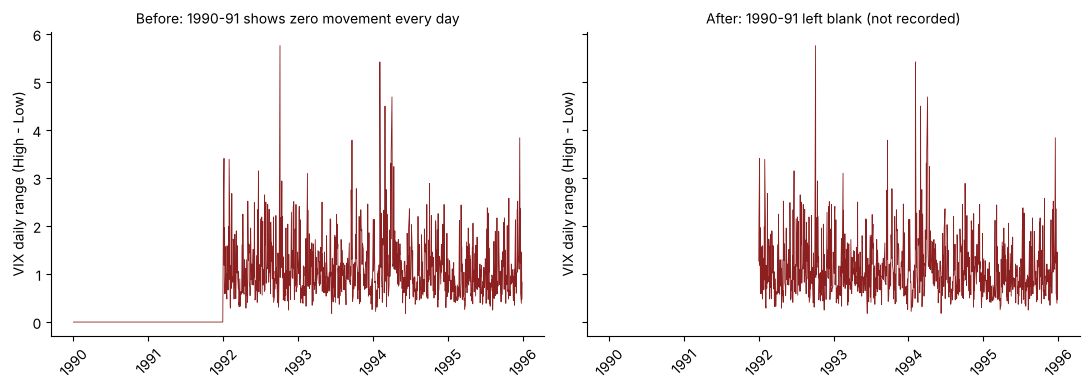

Average daily range 1990-91 BEFORE fix: 0.0
Average daily range 1992-95 (real data): 1.11


In [14]:
# Daily range (High - Low) is what the fake 1990-91 values break
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, sharex=True)
for ax, df, title in [(axes[0], vix_raw, "Before: 1990-91 shows zero movement every day"),
                      (axes[1], vix, "After: 1990-91 left blank (not recorded)")]:
    part = df[df["DATE"] < "1996-01-01"]
    ax.plot(part["DATE"], part["HIGH"] - part["LOW"], color="#8c1f1f", linewidth=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("VIX daily range (High - Low)")
    ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

print("Average daily range 1990-91 BEFORE fix:", round((vix_raw["HIGH"] - vix_raw["LOW"])[vix_raw["DATE"] < "1992-01-01"].mean(), 2))
print("Average daily range 1992-95 (real data):", round((vix["HIGH"] - vix["LOW"])[vix["DATE"].between("1992-01-01", "1995-12-31")].mean(), 2))

### Check VIX

In [15]:
ok = vix.dropna(subset=["OPEN", "HIGH", "LOW"])
assert ((ok["OPEN"] >= ok["LOW"]) & (ok["OPEN"] <= ok["HIGH"])).all()
assert ((vix["CLOSE"] >= vix["LOW"]) | vix["LOW"].isna()).all()
assert not (vix["DATE"] == "2004-06-11").any()
assert vix["DATE"].is_unique and vix["CLOSE"].notna().all()
print("VIX checks passed")
print("Rows:", len(vix_raw), "->", len(vix), "| Close_Only:", vix["Close_Only"].sum(), "| Open_Invalid:", vix["Open_Invalid"].sum())
vix.to_csv(f"{OUT}/cboe_vix_daily_cleaned.csv", index=False)

VIX checks passed
Rows: 9278 -> 9277 | Close_Only: 505 | Open_Invalid: 47


---
## Summary

| Data set | Failure | Fix |
|---|---|---|
| CPI | October 2025 missing (government shutdown) | Added the month back, interpolated value, flagged `Estimated` |
| CPI | `Inflation` column is month over month, not yearly, and Nov 2025 was really a 2-month change | Recalculated as `MoM_Change_%`, added `YoY_Inflation_%`, flagged rows using the estimate |
| VIX | 1990-91 Open/High/Low were copies of the Close | Set to empty, flagged `Close_Only` |
| VIX | 47 days with Open outside High-Low | Set Open to empty, flagged `Open_Invalid` |
| VIX | Row for June 11, 2004 when the market was closed | Removed the row |

The main thing I learned is that both data sets came from official sources and looked clean at first (no missing values in the VIX at all), but they still had problems that would have given wrong charts. Running simple logic checks like "every month present" or "low ≤ open ≤ high" catches things you'd never see just by scrolling through the file. I also tried to flag every change instead of just overwriting values, so anyone using the cleaned files can see what's real and what was repaired.